In [ ]:
# советую делать в изолированной среде Python 3.11, на 3.15 PyTorch на мак не идет

In [1]:
COMMIT_HASH = "b8b4de3057ea4cafc3f263bfcf314f679b637db1"
!if [ -d dgm_utils ]; then rm -Rf dgm_utils; fi
!git clone https://github.com/r-isachenko/dgm_utils.git
%cd dgm_utils
!git checkout {COMMIT_HASH}
!pip install ./
%cd ./..
!rm -Rf dgm_utils

Cloning into 'dgm_utils'...
remote: Enumerating objects: 228, done.
remote: Counting objects: 100% (228/228), done.
remote: Compressing objects: 100% (172/172), done.
remote: Total 228 (delta 148), reused 107 (delta 55), pack-reused 0 (from 0)
Receiving objects: 100% (228/228), 55.60 KiB | 749.00 KiB/s, done.
Resolving deltas: 100% (148/148), done.
/Users/anikadolgova/Downloads/dgm_utils
Note: switching to 'b8b4de3057ea4cafc3f263bfcf314f679b637db1'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at b8b4de3 Fix AM

In [1]:
from dgm_utils import train_model
from dgm_utils import show_samples, visualize_images, load_dataset
from dgm_utils import BaseModel

/Users/anikadolgova/Downloads/.venv311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data

"""
if torch.cuda.is_available():
    DEVICE = "cuda"
    print('GPU found :)') 
else: 
    DEVICE = "cpu"
    print('GPU not found :(') 
"""

# привет макосникам

if torch.cuda.is_available():
    DEVICE = "cuda"
    print('GPU (CUDA) found :)')
elif torch.backends.mps.is_available():
    DEVICE = "mps"
    print('GPU (Apple Silicon MPS) found :)') # тут гпу макоса ищем
else:
    DEVICE = "cpu"
    print('GPU not found :(')

GPU (Apple Silicon MPS) found :)


### Architecture

Начнем с **the multihead attention block**. Каждый блок multihead attention вычисляет вложение
$$
    \text{Attention}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \text{softmax}\left(\frac{\mathbf{Q}\mathbf{K}^T}{\sqrt{d_k}}\right) \mathbf{V},
$$
где $\mathbf{Q}, \mathbf{K}, \mathbf{V}$ - матрицы запроса/ключа/значения, полученные с использованием линейной проекции $\mathbf{h}^l$.

**Чтобы сделать модель авторегрессионной, мы внесем следующие изменения:

1. Мы применим верхнюю треугольную маску к матрице логитов внимания attention logits ($\mathbf{Q}\mathbf{K}^T$).Замаскированные значения задаются близко к минус бесконечности, поэтому после softmax они станут нулевыми.
2. Во время обучения мы добавим маркер "начало последовательности" во входной тензор и добавим последний пиксель.

Примечание: мы будем использовать порядок растра, чтобы определить, какие пиксели идут первыми. Для каждого пикселя предсказанная вероятность обусловлена всеми предыдущими пикселями.

In [3]:
class MultiheadAttention(nn.MultiheadAttention):
    def __init__(self, embed_dim: int, num_heads: int) -> None:
        super().__init__(embed_dim, num_heads)

# это и есть каузальная маска чтобы смотреть предыдущие пиксели

    def get_attention_mask(self, x: torch.Tensor) -> torch.Tensor:
        n = x.size(0)
        attention_mask = torch.full((n, n), float('-inf'), device=x.device, dtype=x.dtype)
        attention_mask = torch.triu(attention_mask, diagonal=1)
        return attention_mask

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        attn_mask = self.get_attention_mask(x)
        return super().forward(x, x, x, attn_mask=attn_mask, need_weights=False)[0]


def test_attention_mask() -> None:
    x = torch.zeros(2, 4, 16)  # (pixel_num, batch_size, emb_dim)
    mask = np.array([[0.0, -np.inf], [0.0, 0.0]])
    layer = MultiheadAttention(16, 8)
    attention_mask = layer.get_attention_mask(x)
    assert attention_mask.size() == (x.size(0), x.size(0))
    assert np.allclose(attention_mask.numpy(), mask)
    out = layer(x)
    assert x.size() == out.size()


test_attention_mask()

Now we will define **the decoder block** which transforms the tensor as follows:
1. нормализуем входной тензор h
2. применяем многоголовое внимание (казуальная маска из блока выше) и добавляем исходный h чтобы градиент не затух
3. снова нормализуем, пропускаем через полносвязную сеть (MLP) и опять добавляем остаточную связь чтобы градиент не затух
\begin{gather}
    \mathbf{n}^l = \text{layer\_norm}_1\left(\mathbf{h}^l\right), \notag \\
    \mathbf{a}^l = \mathbf{h}^l + \text{multihead\_attention}\left(\mathbf{n}^l\right), \notag \\
    \mathbf{h}^{l+1} = \mathbf{a}^l + \text{MLP}\left(\text{layer\_norm}_2\left(a^l\right)\right). \notag
\end{gather}

The $l^{\text{th}}$ block receives a tensor $\mathbf{h}^l$ with shape `(pixel_num, batch_size, emb_dim)` where `pixel_num` is a total number of pixels $(32 \times 32)$ and `emb_dim` is a hyperparameter for the size of the embeddings.

Теперь мы определим блок декодера (decoder block), который преобразует тензор следующим образом:
\begin{gather}
    \mathbf{n}^l = \text{layer\_norm}_1\left(\mathbf{h}^l\right), \notag \\
    \mathbf{a}^l = \mathbf{h}^l + \text{multihead\_attention}\left(\mathbf{n}^l\right), \notag \\
    \mathbf{h}^{l+1} = \mathbf{a}^l + \text{MLP}\left(\text{layer\_norm}_2\left(a^l\right)\right). \notag
\end{gather}

$l^{\text{th}}$-й блок получает тензор $\mathbf{h}^l$
  формы `(pixel_num, batch_size, emb_dim)`, где `pixel_num` — общее количество пикселей 
(
32
×
32
)
(32×32), а `emb_dim` — гиперпараметр, задающий размер эмбеддингов.

In [4]:
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, num_heads: int, mlp_ratio: int = 4) -> None:
        super().__init__()
        assert embed_dim % num_heads == 0
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiheadAttention(embed_dim, num_heads)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(embed_dim * mlp_ratio, embed_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # нормализация
        n = self.norm1(x) 
        # остаточная связь, не заменяем старый x новым результатом, а добавляем новую информацию к старой
        a = x + self.attn(n)
        # два линейных слоя с активацией GELU между ними
        h_next = a + self.mlp(self.norm2(a))
        return h_next


def test_decoder_block() -> None:
    block = TransformerBlock(embed_dim=12, num_heads=4)
    x = torch.zeros(4, 28, 12)
    assert x.shape == block(x).shape


test_decoder_block()

## TarFlow в MNIST

В этой задаче вы реализуете небольшой ** Трансформатор авторегрессионного потока (TarFlow)** в MNIST. TarFlow - это новейшая нормализующая потоковая модель, которая обеспечивает результаты, сопоставимые с современными методами генерации. Для получения более подробной информации прочтите [документ TarFlow](https://arxiv.org/abs/2412.06329) и просмотрите [Лекцию 2](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/lectures/lecture2/Lecture2.pdf) для получения формулы изменения переменных.

Давайте подготовим некоторые непрерывные данные MNIST.

MNIST — это картинки, где каждый пиксель — это целое число от 0 до 255 (градации серого). Но нормализующие потоки (Normalizing Flows) работают только с непрерывными распределениями. Они не умеют работать с дискретными значениями напрямую.

Чтобы сгладить дискретные пиксели, мы делаем две вещи:

1. Масштабируем: делим на 255, чтобы значения были от 0 до 1.
2. Добавляем шум: добавляем маленький случайный шум (например, torch.rand_like(x) / 256), чтобы превратить дискретные значения в непрерывные.

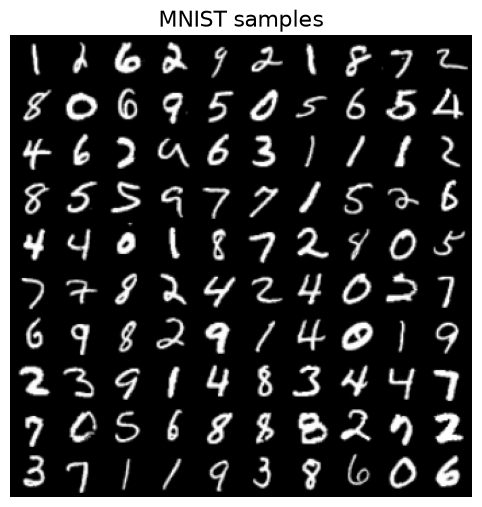

In [5]:
train_data, _, test_data, _ = load_dataset("mnist", flatten=False, binarize=False)
visualize_images(train_data, "MNIST samples")

### Архитектура

Давайте сначала реализуем один блок TarFlowBlock. Как обсуждалось в [Лекции 2](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/lectures/lecture2/Lecture2.pdf), нормализующие потоки используют обратимые преобразования. TarFlow использует конструкцию авторегрессии для определения обратимого преобразования фрагментов изображения.

Пусть $x_i\in\mathbb {R}^D$ является $i$-м входным патчем (из $N$ всего). Каузальный преобразователь предсказывает сдвиг $\mu_i$ и логарифмическую шкалу $\alpha_i$ по сравнению с предыдущими исправлениями. Применяется блок

$$
z_0=x_0,\qquad
z_i=\bigl(x_i-\mu_i(x_{<i})\bigr)\exp\bigl(-\alpha_i(x_{<i})\bigr),
\quad i>0.
$$

Якобиан треугольный, с диагональными записями $\exp(-\alpha_{i,j})$ для $i>0$. Следовательно,

$$
\log|\det J|=-\sum_{i=1}^{N-1}\sum_{j=1}^{D}\alpha_{i,j}.
$$

Мы повторно используем каузальный "трансформерблок" из задачи 2 для прогнозирования сдвигов и логарифмических масштабов. Давайте теперь реализуем `тарфлоублок`.

В основе лежит классическая идея авторегрессионных потоков (MAF), но вместо простого MLP используется мощный каузальный Transformer.
Суть в том, что мы последовательно преобразуем каждый патч изображения, используя информацию только от предыдущих патчей. Используем обратимое преобразование. Вот почему это работает как нормализующий поток: мы можем свободно переходить между исходным пространством изображений и латентным пространством и обратно.

In [6]:
# предсказываем параметры для каждого патча на основе предыдущих

class TarFlowBlock(nn.Module):
    def __init__(
        self,
        patch_dim: int,
        num_patches: int,
        embed_dim: int,
        num_heads: int,
        num_layers: int,
        reverse_order: bool,
    ) -> None:
        super().__init__()
        self.reverse_order = reverse_order

        # проекция патча (patch_dim) в embed_dim
        self.proj = nn.Linear(patch_dim, embed_dim)
        self.pos_emb = nn.Parameter(torch.randn(1, num_patches, embed_dim))
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads) for _ in range(num_layers)
        ])

        # предсказываем сдвиг и лог-масштаб (по patch_dim на каждый)
        self.head = nn.Linear(embed_dim, 2 * patch_dim)

        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def predict_parameters(self, x: torch.Tensor) -> torch.Tensor:
        """x: (batch, length, patch_dim) -> params: (batch, length, 2 * patch_dim)"""
        length = x.size(1)

        pos = self.pos_emb
        if self.reverse_order:
            pos = pos.flip(1)
        pos = pos[:, :length, :]
        h = self.proj(x) + pos
        h = h.transpose(0, 1)
        for block in self.blocks:
            h = block(h)
        h = h.transpose(0, 1)
        parameters = self.head(h)
        return parameters

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        if self.reverse_order:
            x = x.flip(1)
        params = self.predict_parameters(x)
        shifted = torch.zeros_like(params)
        shifted[:, 1:] = params[:, :-1]

        mu, alpha = shifted.chunk(2, dim=-1)

        
        z = (x - mu) * torch.exp(-alpha)
        log_det = -alpha.sum(dim=(1, 2)) 

        if self.reverse_order:
            z = z.flip(1)
        return z, log_det

    def inverse(self, z: torch.Tensor) -> torch.Tensor:
        if self.reverse_order:
            z = z.flip(1)

        batch, N, D = z.shape
        x = torch.zeros_like(z)
        x[:, 0] = z[:, 0]
        for i in range(1, N):
            
            params = self.predict_parameters(x[:, :i])
            mu_i, alpha_i = params[:, -1].chunk(2, dim=-1)
            x[:, i] = z[:, i] * torch.exp(alpha_i) + mu_i

        return x.flip(1) if self.reverse_order else x

Полная модель TarFlow разбивает изображение на участки, применяет несколько блоков TarFlowBlock с чередующимся порядком исправлений (таким образом, участок, оставленный неизменным в одном блоке, может быть преобразован в следующем) и оценивает результирующую латентность в соответствии со стандартным гауссовым априором.

Теперь давайте реализуем это.

Полная модель TarFlow:

1. Масштабирует изображение из $[0, 1]$ в $[-1, 1]$ (это добавляет константу к лог-детерминанту).
2. Разбивает на патчи (patchify) — картинка $(B, C, H, W)$ превращается в последовательность векторов $(B, N, \text{patch\_dim})$.
3. Прогоняет через стек `TarFlowBlock`'ов с чередующимся порядком (forward / reverse), накапливая лог-детерминант.
4. Собирает патчи обратно в картинку (unpatchify) — получаем латент $z$.

Затем `log_prob` использует change-of-variables formula:

$$
\log p(x) = \log p(z) + \log |\det J|
$$

где $z = f(x)$ — прямое преобразование, а $J = \frac{\partial z}{\partial x}$ — его якобиан.

In [7]:
class TarFlow(BaseModel):
    def __init__(
        self,
        input_shape: tuple[int, int],
        n_channels: int,
        patch_size: int,
        embed_dim: int,
        num_heads: int,
        num_layers: int,
        num_blocks: int,
    ) -> None:
        super().__init__()
        assert input_shape[0] % patch_size == 0 and input_shape[1] % patch_size == 0
        self.input_shape = input_shape
        self.n_channels = n_channels
        self.patch_size = patch_size
        num_patches = (input_shape[0] // patch_size) * (input_shape[1] // patch_size)
        patch_dim = n_channels * patch_size * patch_size

        self.prior = torch.distributions.Normal(
            loc=torch.tensor(0.0), scale=torch.tensor(1.0)
        )
        self.blocks = nn.ModuleList([
            TarFlowBlock(
                patch_dim=patch_dim,
                num_patches=num_patches,
                embed_dim=embed_dim,
                num_heads=num_heads,
                num_layers=num_layers,
                reverse_order=(i % 2 == 1),
            )
            for i in range(num_blocks)
        ])

    def patchify(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, C, H, W) -> patches: (B, num_patches, C * p * p)"""
        B, C, H, W = x.shape
        p = self.patch_size
        nh, nw = H // p, W // p
        patches = x.reshape(B, C, nh, p, nw, p)
        patches = patches.permute(0, 2, 4, 1, 3, 5)
        patches = patches.reshape(B, nh * nw, C * p * p)
        return patches

    def unpatchify(self, patches: torch.Tensor) -> torch.Tensor:
        """patches: (B, num_patches, C * p * p) -> x: (B, C, H, W)"""
        B, N, D = patches.shape
        C = self.n_channels
        p = self.patch_size
        H, W = self.input_shape
        nh, nw = H // p, W // p
        x = patches.reshape(B, nh, nw, C, p, p)
        x = x.permute(0, 3, 1, 4, 2, 5)
        x = x.reshape(B, C, H, W)
        return x

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        x = 2 * x - 1
        log_det = x.new_full((x.size(0),), x[0].numel() * np.log(2.0))
        patches = self.patchify(x)
        for block in self.blocks:
            patches, ld = block(patches)
            log_det = log_det + ld
        z = self.unpatchify(patches)
        return z, log_det

    def inverse(self, z: torch.Tensor) -> torch.Tensor:
        patches = self.patchify(z)
        for block in reversed(self.blocks):
            patches = block.inverse(patches)
        x = self.unpatchify(patches)
        return (x + 1) / 2

    def log_prob(self, x: torch.Tensor) -> torch.Tensor:
        self.prior.loc = self.prior.loc.to(self.device)
        self.prior.scale = self.prior.scale.to(self.device)
        z, log_det = self.forward(x)
        log_pz = self.prior.log_prob(z).sum(dim=(1, 2, 3))  # (B,)
        log_prob = log_pz + log_det
        return log_prob

    def loss(self, x: torch.Tensor) -> dict:
        return {"nll_loss": -self.log_prob(x).mean()}

    @torch.no_grad()
    def sample(self, num_samples: int) -> np.ndarray:
        z = torch.randn(num_samples, self.n_channels, *self.input_shape, device=self.device)
        samples = self.inverse(z).cpu().numpy()
        return np.clip(samples, 0.0, 1.0)


### Training

Now we are ready to train TarFlow.

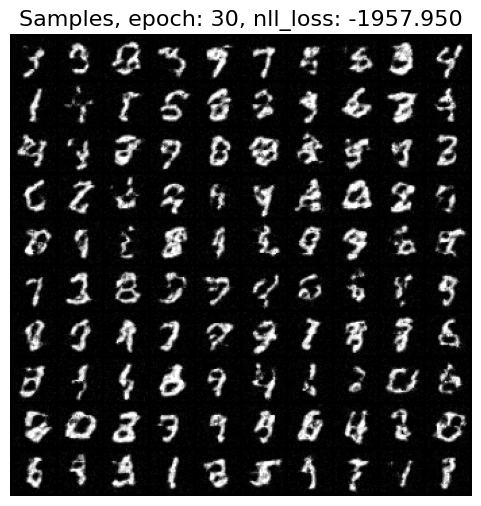

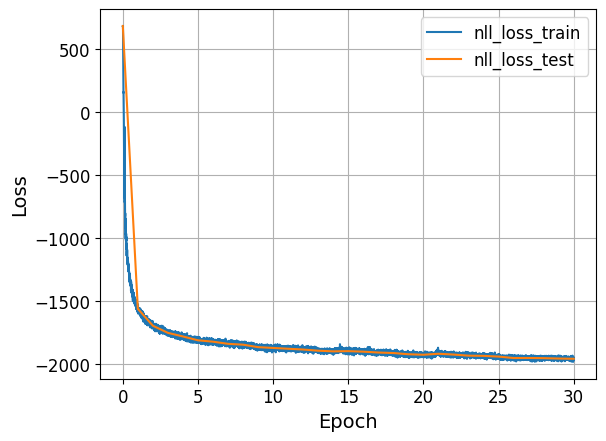

End of the training


In [ ]:
# ====
# your code
# choose these parameters
EPOCHS = 
BATCH_SIZE = 
LR = 

PATCH_SIZE = 
EMB_DIM = 
NUM_HEADS = 
NUM_LAYERS = 
NUM_BLOCKS = 
# ====

tarflow = TarFlow(
    input_shape=(32, 32),
    n_channels=1,
    patch_size=PATCH_SIZE,
    embed_dim=EMB_DIM,
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    num_blocks=NUM_BLOCKS,
)

# we add Gaussian noise to smooth the many exact zeros in MNIST
# this helps the flow learn a continuous density and improves sample quality
class GaussianNoiseDataset(data.Dataset):
    def __init__(self, images, noise_std_scaled: float) -> None:
        self.images = images
        self.noise_std = noise_std_scaled / 2

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, index: int) -> torch.Tensor:
        x = torch.as_tensor(self.images[index], dtype=torch.float32)
        return x + self.noise_std * torch.randn_like(x)

train_loader = data.DataLoader(
    GaussianNoiseDataset(train_data, 0.05), batch_size=BATCH_SIZE, shuffle=True
)
test_loader = data.DataLoader(
    GaussianNoiseDataset(test_data, 0.05), batch_size=BATCH_SIZE
)

# choose any optimizer/scheduler as you want
optimizer = torch.optim.AdamW(tarflow.parameters(), lr=LR)

train_model(
    tarflow,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    gradient_clip_val=1.0,
    device=DEVICE,
    visualize_samples=True,
    loss_key="nll_loss",
    use_amp=True,
)

Finally, let's draw samples from TarFlow.

In [ ]:
samples = tarflow.sample(4)
show_samples(samples, title="TarFlow samples", nrow=2)